# EDA-03 Scales

In [1]:
import sys
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from scipy.stats import iqr

from secomml.data_loader import load_secom
from secomml.data_eda import profile
from secomml.data_pipeline import secom_simple_imputer, secom_drop_zero_variance_features

**NOTE** all analysis in this notebook assume MEAN IMPUTER

In [2]:
secom = (
    load_secom("../data/raw/secom.zip")
    .drop(columns=['timestamp'])
    .pipe(secom_drop_zero_variance_features)
    .pipe(secom_simple_imputer)
)
secom

,faulty,x0,x1,x2,x3,x4,x6,x7,x8,x9,x10,x11,x12,x14,x15,x16,x17,x18,x19,x20,x21,x22,x23,x24,x25,x26,x27,x28,x29,x30,x31,x32,x33,x34,x35,x36,x37,x38,x39,x40,...,x550,x551,x552,x553,x554,x555,x556,x557,x558,x559,x560,x561,x562,x563,x564,x565,x566,x567,x568,x569,x570,x571,x572,x573,x574,x575,x576,x577,x578,x579,x580,x581,x582,x583,x584,x585,x586,x587,x588,x589
0,0.0,3030.93,2564.00,2187.7333,1411.1265,1.3602,97.6133,0.1242,1.500500,0.016200,-0.003400,0.945500,202.439600,7.955800,414.871000,10.043300,0.968000,192.396300,12.5190,1.4026,-5419.00,2916.50,-4043.75,751.00,0.8955,1.7730,3.0490,64.2333,2.0222,0.1632,3.5191,83.3971,9.5126,50.6170,64.2588,49.3830,66.3141,86.9555,117.5132,61.29,...,12.93,0.78,0.1827,5.7349,0.3363,39.8842,3.2687,1.0297,1.0344,0.4385,0.1039,42.3877,262.729683,0.679641,6.444985,0.14561,2.61087,0.060086,2.452417,21.117674,533.8500,2.1113,8.95,0.3157,3.0624,0.1026,1.6765,14.9509,0.021615,0.016829,0.005396,97.934373,0.5005,0.0118,0.0035,2.3630,0.021458,0.016475,0.005283,99.670066
1,0.0,3095.78,2465.14,2230.4222,1463.6606,0.8294,102.3433,0.1247,1.496600,-0.000500,-0.014800,0.962700,200.547000,10.154800,414.734700,9.259900,0.970100,191.287200,12.4608,1.3825,-5441.50,2604.25,-3498.75,-1640.25,1.2973,2.0143,7.3900,68.4222,2.2667,0.2102,3.4171,84.9052,9.7997,50.6596,64.2828,49.3404,64.9193,87.5241,118.1188,78.25,...,16.00,1.33,0.2829,7.1196,0.4989,53.1836,3.9139,1.7819,0.9634,0.1745,0.0375,18.1087,262.729683,0.679641,6.444985,0.14561,2.61087,0.060086,2.452417,21.117674,535.0164,2.4335,5.92,0.2653,2.0111,0.0772,1.1065,10.9003,0.009600,0.020100,0.006000,208.204500,0.5019,0.0223,0.0055,4.4447,0.009600,0.020100,0.006000,208.204500
2,1.0,2932.61,2559.94,2186.4111,1698.0172,1.5102,95.4878,0.1241,1.443600,0.004100,0.001300,0.961500,202.017900,9.515700,416.707500,9.314400,0.967400,192.703500,12.5404,1.4123,-5447.75,2701.75,-4047.00,-1916.50,1.3122,2.0295,7.5788,67.1333,2.3333,0.1734,3.5986,84.7569,8.6590,50.1530,64.1114,49.8470,65.8389,84.7327,118.6128,14.37,...,16.16,0.85,0.0857,7.1619,0.3752,23.0713,3.9306,1.1386,1.5021,0.3718,0.1233,24.7524,267.064000,0.903200,1.100000,0.62190,0.41220,0.256200,0.411900,68.848900,535.0245,2.0293,11.21,0.1882,4.0923,0.0640,2.0952,9.2721,0.058400,0.048400,0.014800,82.860200,0.4958,0.0157,0.0039,3.1745,0.058400,0.048400,0.014800,82.860200
3,0.0,2988.72,2479.90,2199.0333,909.7926,1.3204,104.2367,0.1217,1.488200,-0.012400,-0.003300,0.962900,201.848200,9.605200,422.289400,9.692400,0.968700,192.155700,12.4782,1.4011,-5468.25,2648.25,-4515.00,-1657.25,1.3137,2.0038,7.3145,62.9333,2.6444,0.2071,3.3813,84.9105,8.6789,50.5100,64.1125,49.4900,65.1951,86.6867,117.0442,76.90,...,131.68,39.33,0.6812,56.9303,17.4781,161.4081,35.3198,54.2917,1.1613,0.7288,0.2710,62.7572,268.228000,0.651100,7.320000,0.16300,3.56110,0.067000,2.729000,25.036300,530.5682,2.0253,9.33,0.1738,2.8971,0.0525,1.7585,8.5831,0.020200,0.014900,0.004400,73.843200,0.4990,0.0103,0.0025,2.0544,0.020200,0.014900,0.004400,73.843200
4,0.0,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.3967,0.1235,1.503100,-0.003100,-0.007200,0.956900,201.942400,10.566100,420.592500,10.338700,0.973500,191.603700,12.4735,1.3888,-5476.25,2635.25,-3987.50,117.00,1.2887,1.9912,7.2748,62.8333,3.1556,0.2696,3.2728,86.3269,8.7677,50.2480,64.1511,49.7520,66.1542,86.1468,121.4364,76.39,...,19.63,1.98,0.4287,9.7608,0.8311,70.9706,4.9086,2.5014,0.9778,0.2156,0.0461,22.0500,262.729683,0.679641,6.444985,0.14561,2.61087,0.060086,2.452417,21.117674,532.0155,2.0275,8.83,0.2224,3.1776,0.0706,1.6597,10.9698,0.021615,0.016829,0.005396,97.934373,0.4800,0.4766,0.1045,99.3032,0.020200,0.014900,0.004400,73.843200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1562,0.0,2899.41,2464.36,2179.7333,3085.3781,1.484

In [65]:
X = secom.drop(columns='faulty')
y = secom['faulty']
print(f'Assure #NA: {secom.isna().sum().sum()}')

Assure #NA: 0


### Vars Distribution

In [66]:
from scipy.stats import iqr

feat_by_median = X.median().sort_values().index
feat_by_variance = X.var().sort_values().index
feat_by_iqr = X.apply(iqr, nan_policy='omit').sort_values().index
feat_by_range = (X.max() - X.min()).sort_values().index

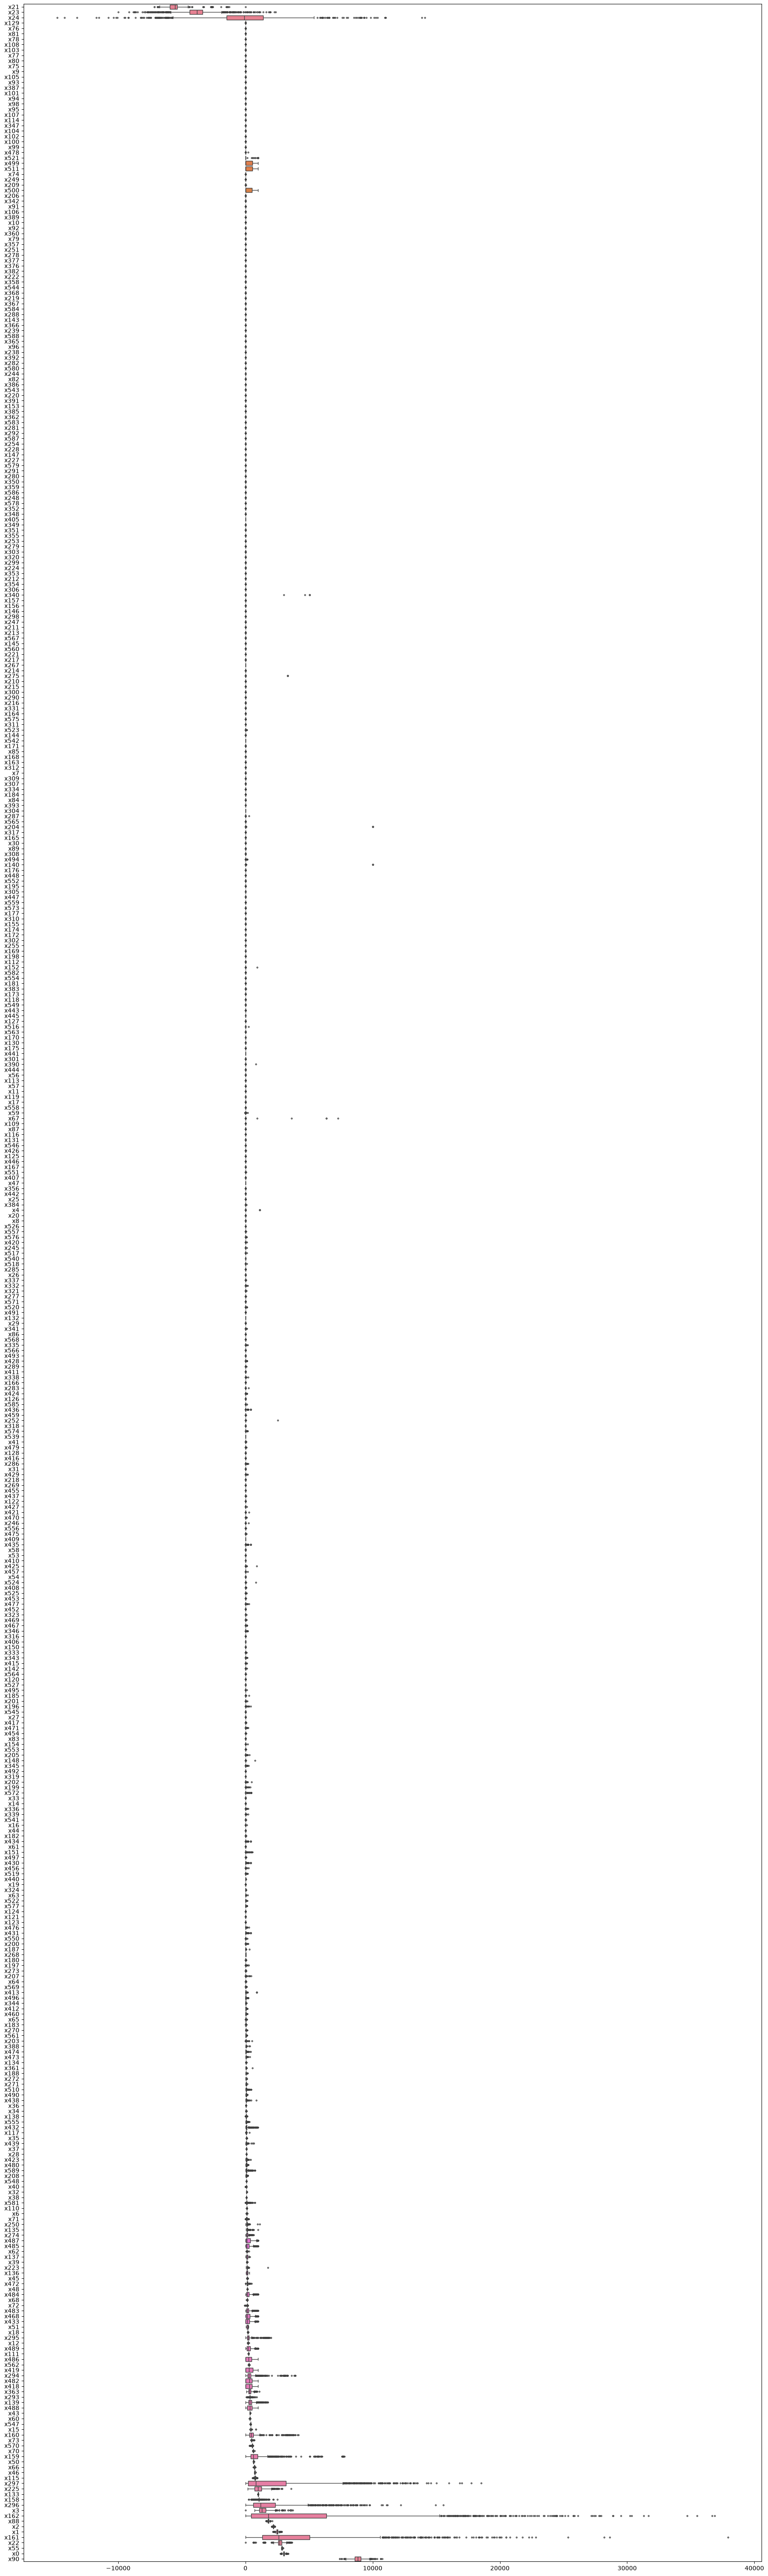

In [67]:
plt.figure(figsize=(18,60))
sns.boxplot(data=X[feat_by_median], orient='h', showfliers=True, fliersize=2)
plt.tight_layout()
plt.show()

Log Scale

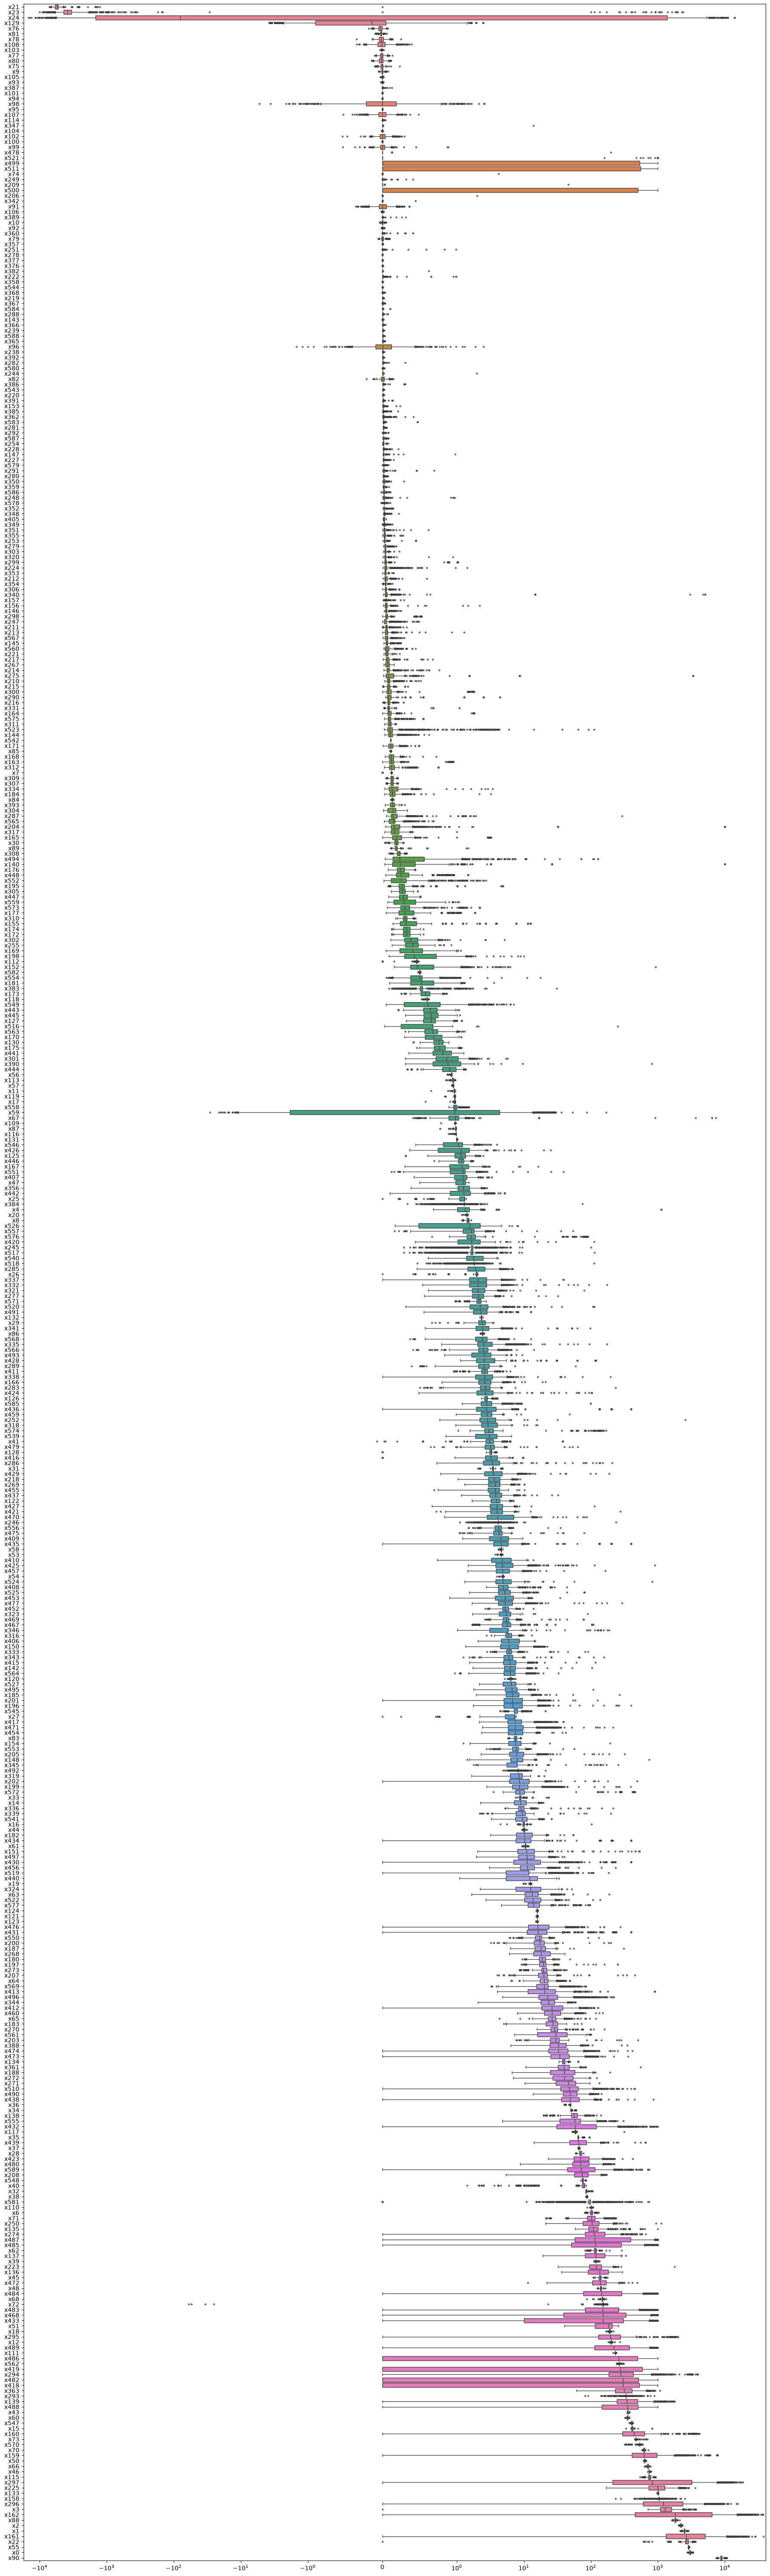

In [68]:
plt.figure(figsize=(18,60))
sns.boxplot(data=X[feat_by_median], orient='h', showfliers=True, fliersize=2)
plt.xscale("symlog", linthresh=1)
plt.tight_layout()
plt.show()

##### Conclusion

* Too many variables with big differences in magnitude. Plots are difficult to read
    * (**TODO** scaling/normalization needed?)
* **TODO** outliers visible - check this
* **Variance** of some vars looks very small (is this a problem?)
* Log scale does not seems to help, rather obscure the view.


### Median & IQR & Variances Distributions

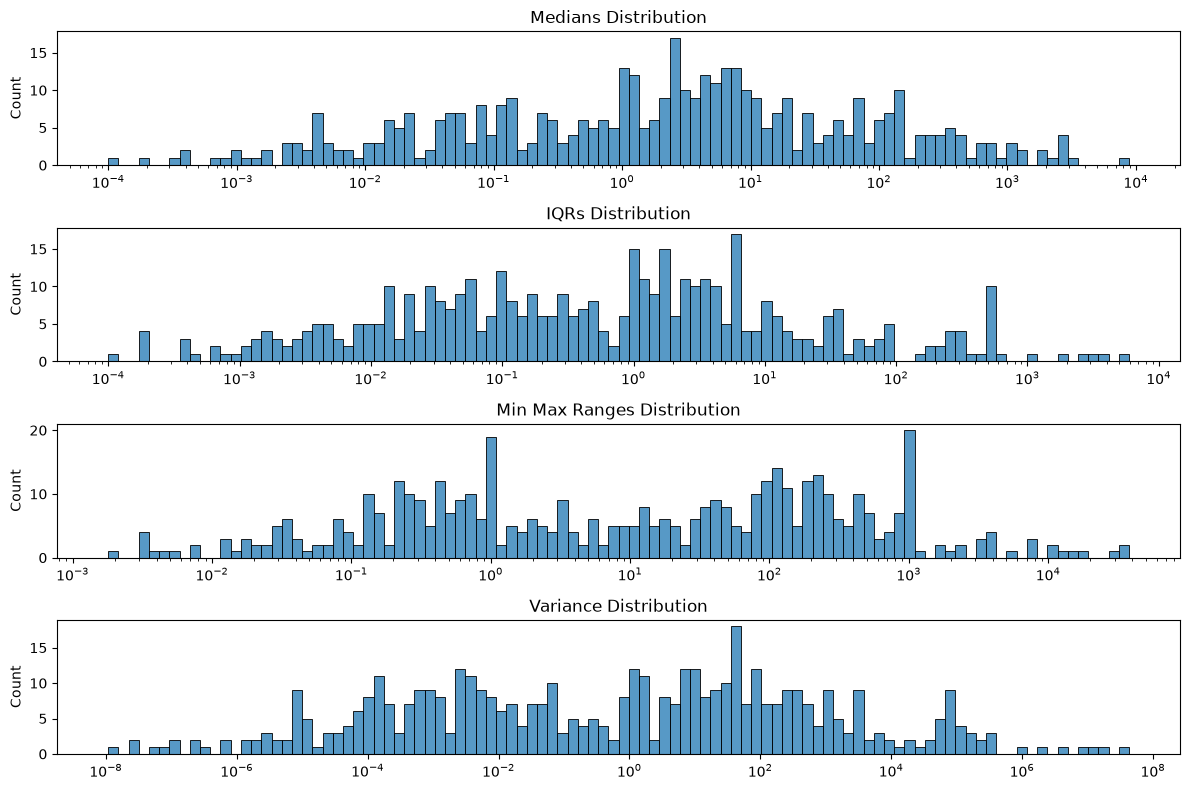

In [69]:
medians = X.median()
IQRs = X.apply(iqr)
ranges = (X.max() - X.min())
variances = X.var()

fig, ax = plt.subplots(nrows=4, ncols=1, figsize=(12, 8))
sns.histplot(medians, ax=ax[0], log_scale=(True, False), stat='count', bins=100).set_title('Medians Distribution')
sns.histplot(IQRs, ax=ax[1], log_scale=(True, False), stat='count', bins=100).set_title('IQRs Distribution')
sns.histplot(ranges, ax=ax[2], log_scale=(True, False), stat='count', bins=100).set_title('Min Max Ranges Distribution')
sns.histplot(variances, ax=ax[3], log_scale=(True, False), stat='count', bins=100).set_title('Variance Distribution')
plt.tight_layout()
plt.show()

Median vs IQR

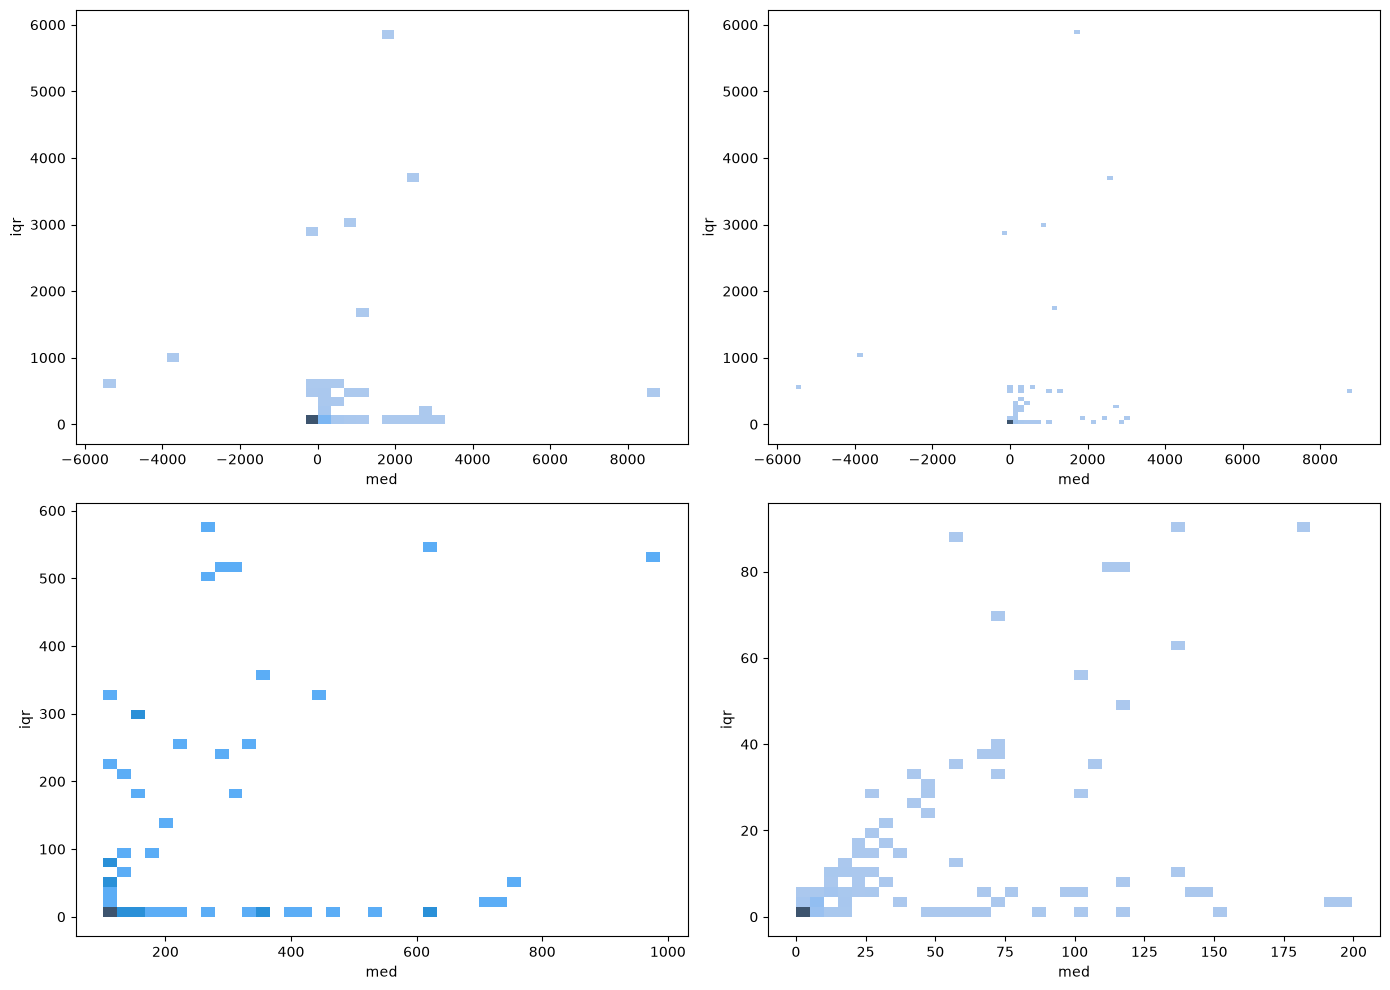

In [70]:
stats = pd.DataFrame({'med':X.median(), 'iqr':X.apply(iqr)})
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(14,10))
sns.histplot(data=stats, x='med', y='iqr', ax=ax[0][0])
sns.histplot(data=stats, x='med', y='iqr', bins=100, ax=ax[0][1])
sns.histplot(data=stats[(stats['med'] < 1000) & (stats['med'] > 100) & (stats['iqr'] < 1000)], x='med', y='iqr', bins=40, ax=ax[1][0])
sns.histplot(data=stats[(stats['med'] < 200) & (stats['med'] > 0) & (stats['iqr'] < 100)], x='med', y='iqr', ax=ax[1][1])
plt.tight_layout()
plt.show()

### Variance assassement

In [71]:
var = X.var()
var_small = var[(var < 1e-6)].index
var.loc[var_small]

x94     3.020675e-08
x95     1.085926e-08
x100    1.259220e-07
x101    4.854930e-08
x104    7.227809e-07
x220    5.684117e-07
x278    1.149586e-07
x357    2.490025e-07
x358    2.238421e-08
x376    2.851653e-07
x377    2.173816e-07
x544    8.722063e-08
dtype: float64

In [72]:
stats = pd.DataFrame({'mean': X.mean(), 'std': X.std(), 'var': X.var()})
stats['cv'] = ((X.std() / X.mean().abs()) * 100)
stats['V_2'] = np.sqrt(X.var()/ (X.var() + X.mean()**2))
stats['q99'] = X.quantile(.99)
stats.sort_values('var', ascending=False)

,mean,std,var,cv,V_2,q99
x162,4797.154633,6549.383070,4.289442e+07,136.526411,0.806741,27327.320000
x161,4066.850479,4236.537140,1.794825e+07,104.172434,0.721406,19635.060000
x297,2342.826978,3224.863024,1.039974e+07,137.648365,0.809038,12969.675500
x24,-298.598136,2900.835956,8.414849e+06,971.484951,0.994744,9033.390000
x296,1879.228369,1973.849716,3.896083e+06,105.035117,0.724253,9029.031410
...,...,...,...,...,...,...
x544,0.002509,0.000295,8.722063e-08,11.769936,0.116892,0.003234
x101,-0.000007,0.000220,4.854930e-08,3043.798752,0.999461,0.000600
x94,-0.000029,0.000174,3.020675e-08,596.270729,0.986227,0.000400
x358,0.002443,0.000150,2.238421e-08,6.124372,0.061129,0.003000


##### Conclusion

This lead to notihing interesting currently

### Outliers: Mean vs Trimmed-Mean

In [73]:
from scipy.stats import trim_mean
stats = pd.DataFrame({'mean': X.mean(), 'tmean': X.apply(lambda x: trim_mean(x, 0.01))})
stats['%diff'] = stats['tmean'] / stats['mean'] * 100
stats.sort_values('%diff')

,mean,tmean,%diff
x478,0.128123,0.000000,0.000000
x74,0.002688,0.000000,0.000000
x342,0.000286,0.000000,0.000000
x347,0.008914,0.000000,0.000000
x209,0.029564,0.000000,0.000000
...,...,...,...
x102,0.001115,0.001175,105.401641
x101,-0.000007,-0.000008,107.344499
x91,0.002440,0.002623,107.517123
x108,-0.010789,-0.011645,107.939646


##### Conclusion

Some variables have %50 difference betwean `mean` and `trimmed-mean` (1% from each side). This indicate outliers in variables.

**TODO**: Check outliers correlation with positive class

**TODO**: Is this a problem? Consider how to deal with outliers in pipeline. Test model accuracy w/wo outliers.

### Vars Scaling

##### Standardization

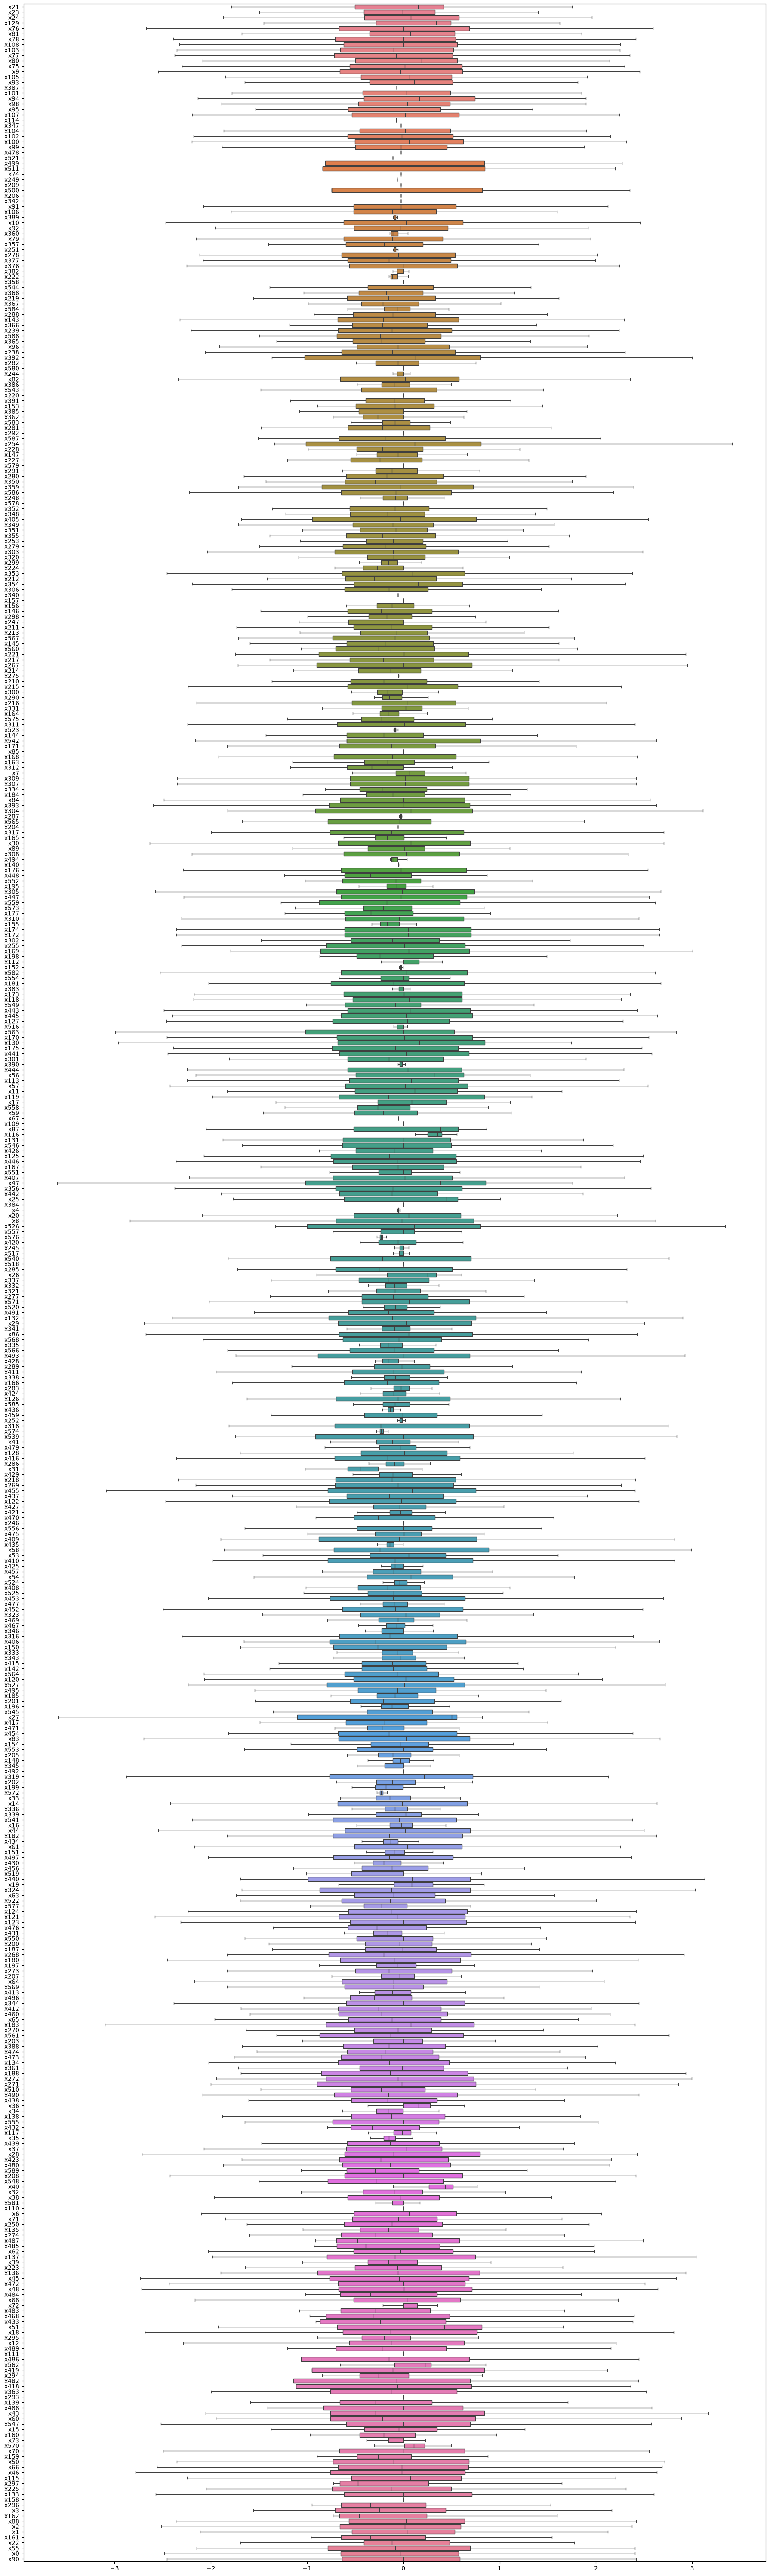

In [74]:
from secomml.data_pipeline import secom_standard_scaler
plt.figure(figsize=(18,60))
sns.boxplot(data=secom_standard_scaler(X[feat_by_median]), orient='h', showfliers=False)
plt.tight_layout()
plt.show()

##### Normalization (0:1)

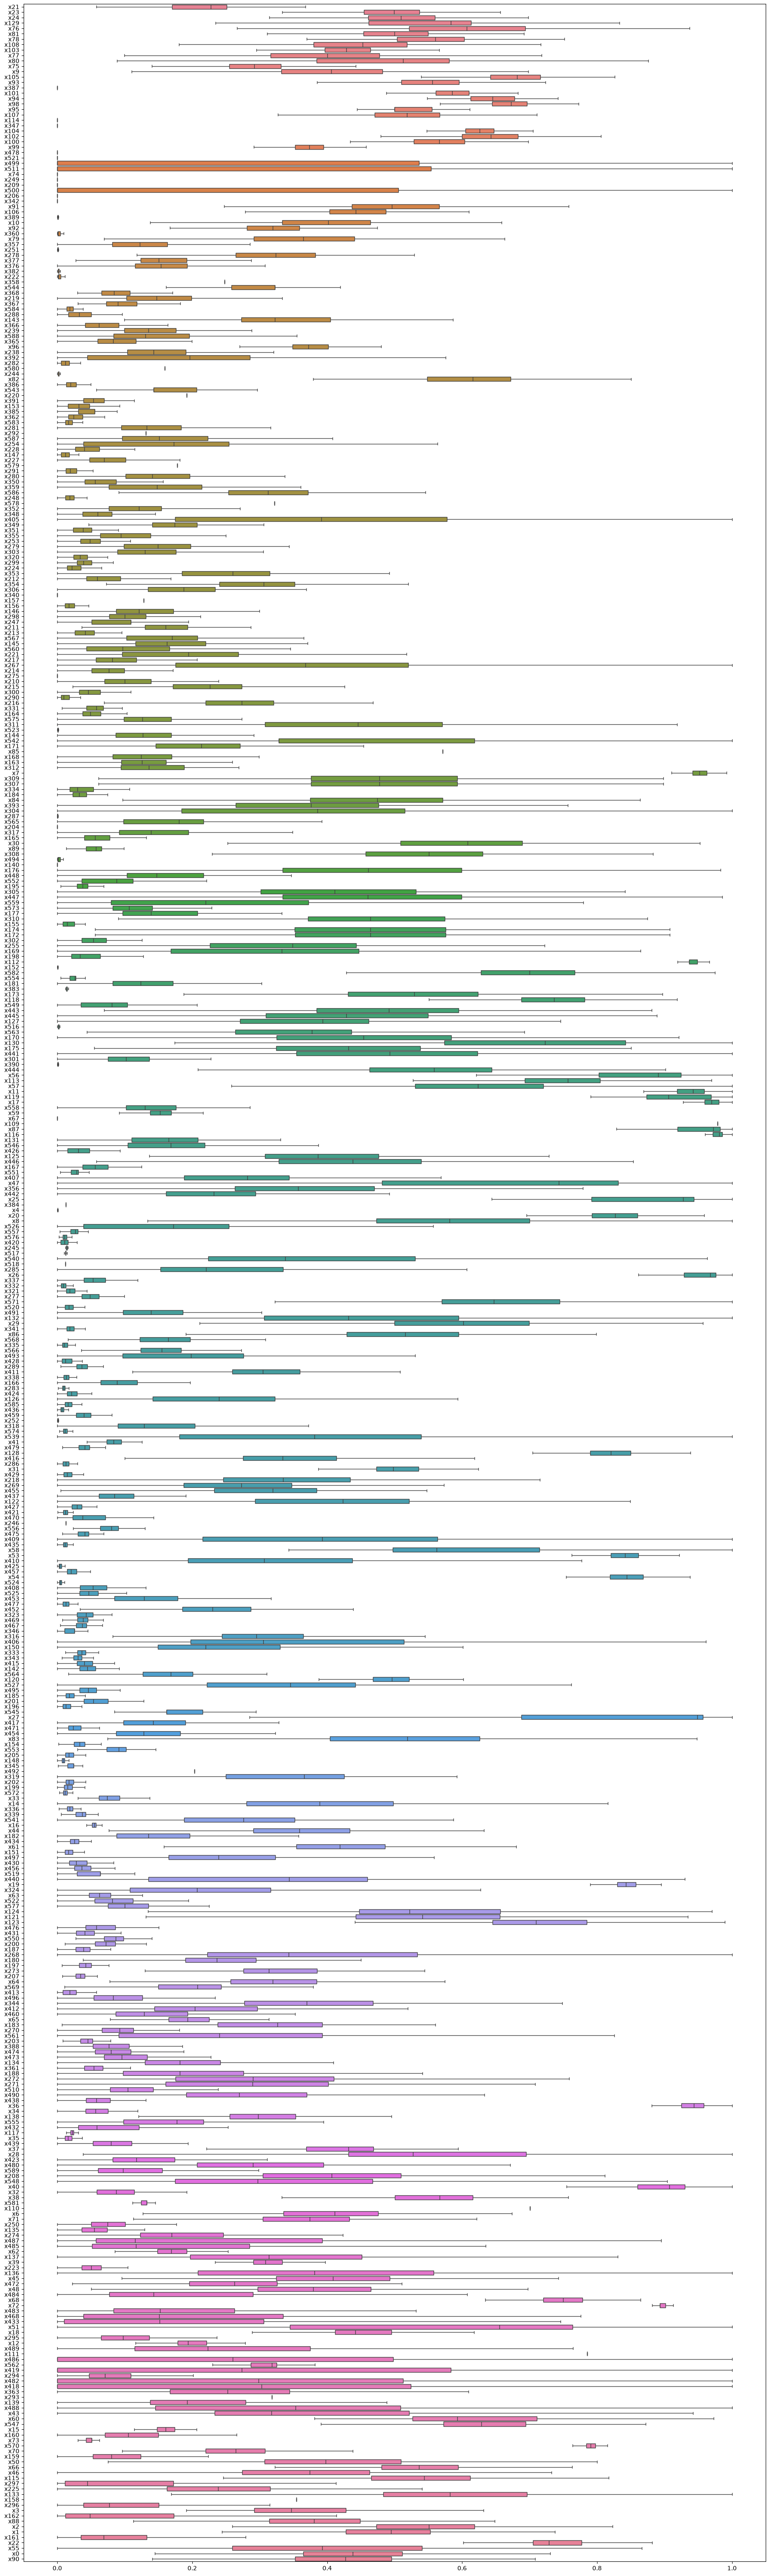

In [75]:
from secomml.data_pipeline import secom_minmax_scaler
plt.figure(figsize=(18,60))
sns.boxplot(data=secom_minmax_scaler(X[feat_by_median]), orient='h', showfliers=False)
plt.tight_layout()
plt.show()

##### Normalization (-1:1)

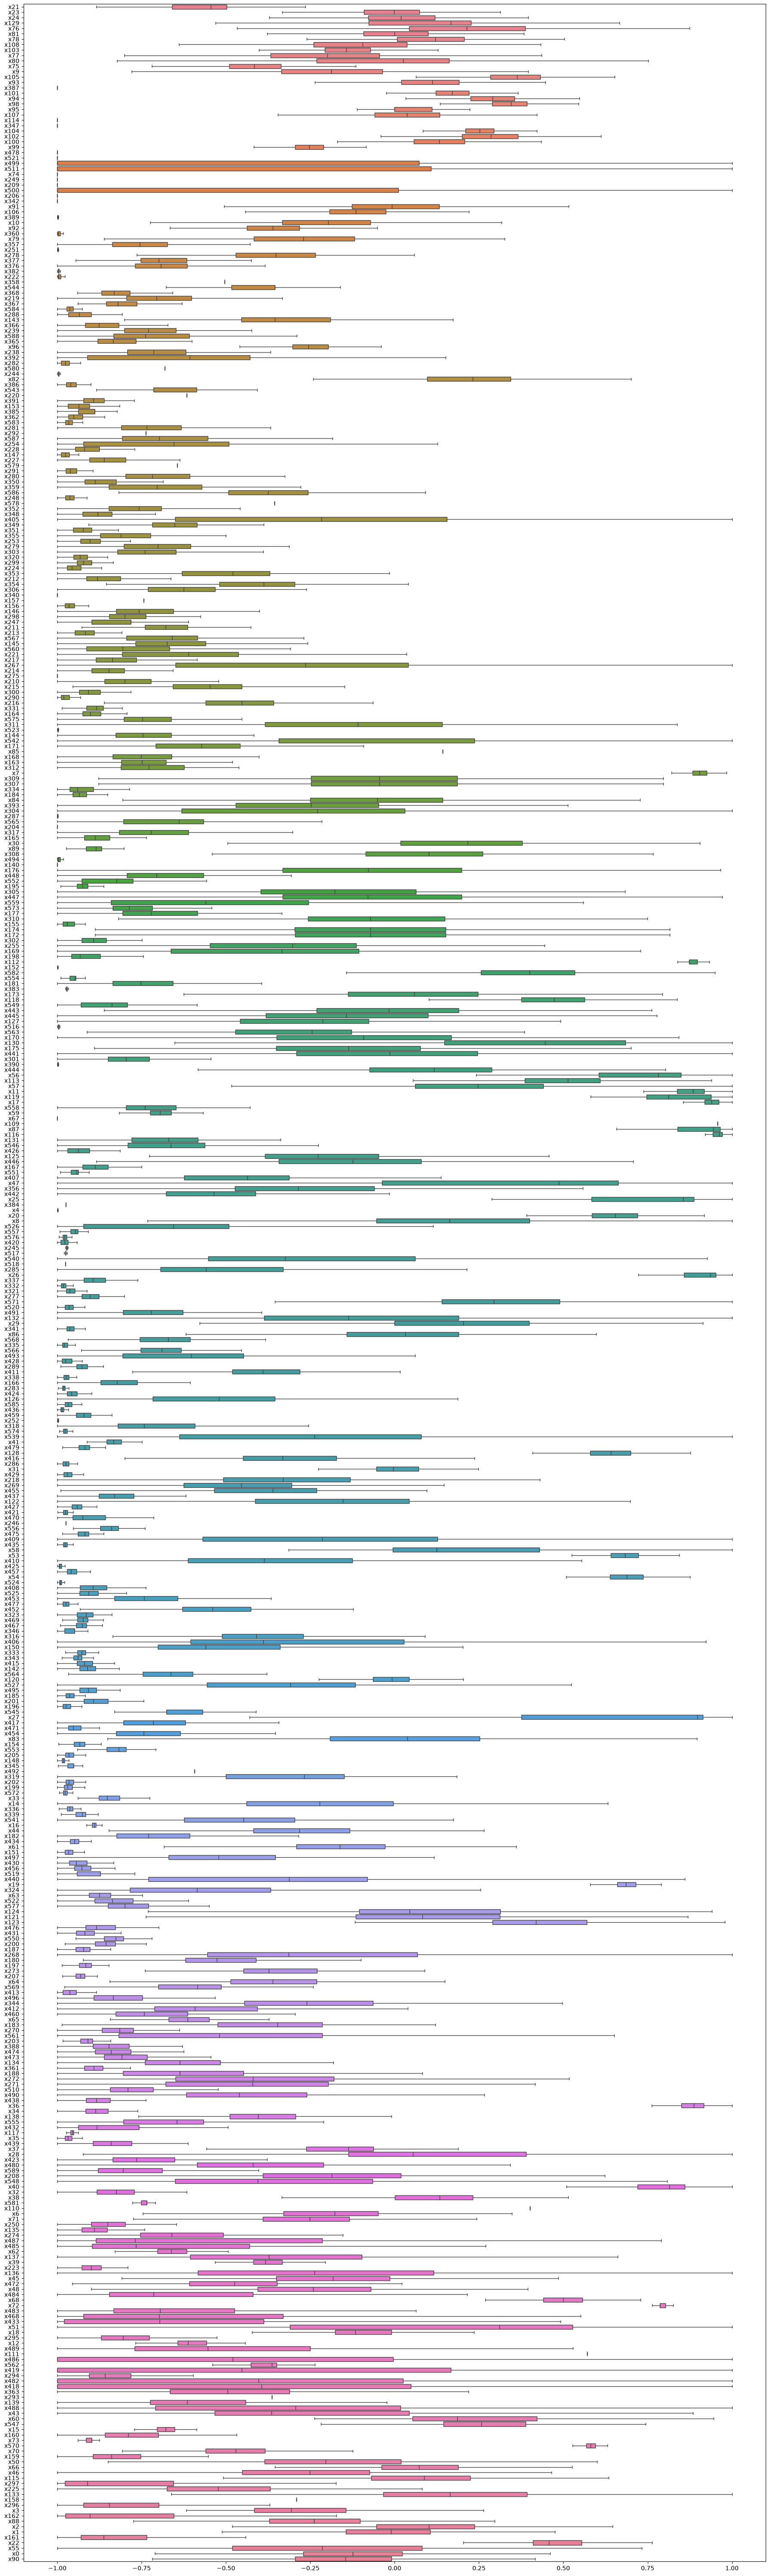

In [76]:
from secomml.data_pipeline import secom_minmax_scaler
plt.figure(figsize=(18,60))
sns.boxplot(data=secom_minmax_scaler(X[feat_by_median], feature_range=(-1, 1)), orient='h', showfliers=False)
plt.tight_layout()
plt.show()

##### Normalization L1 L2

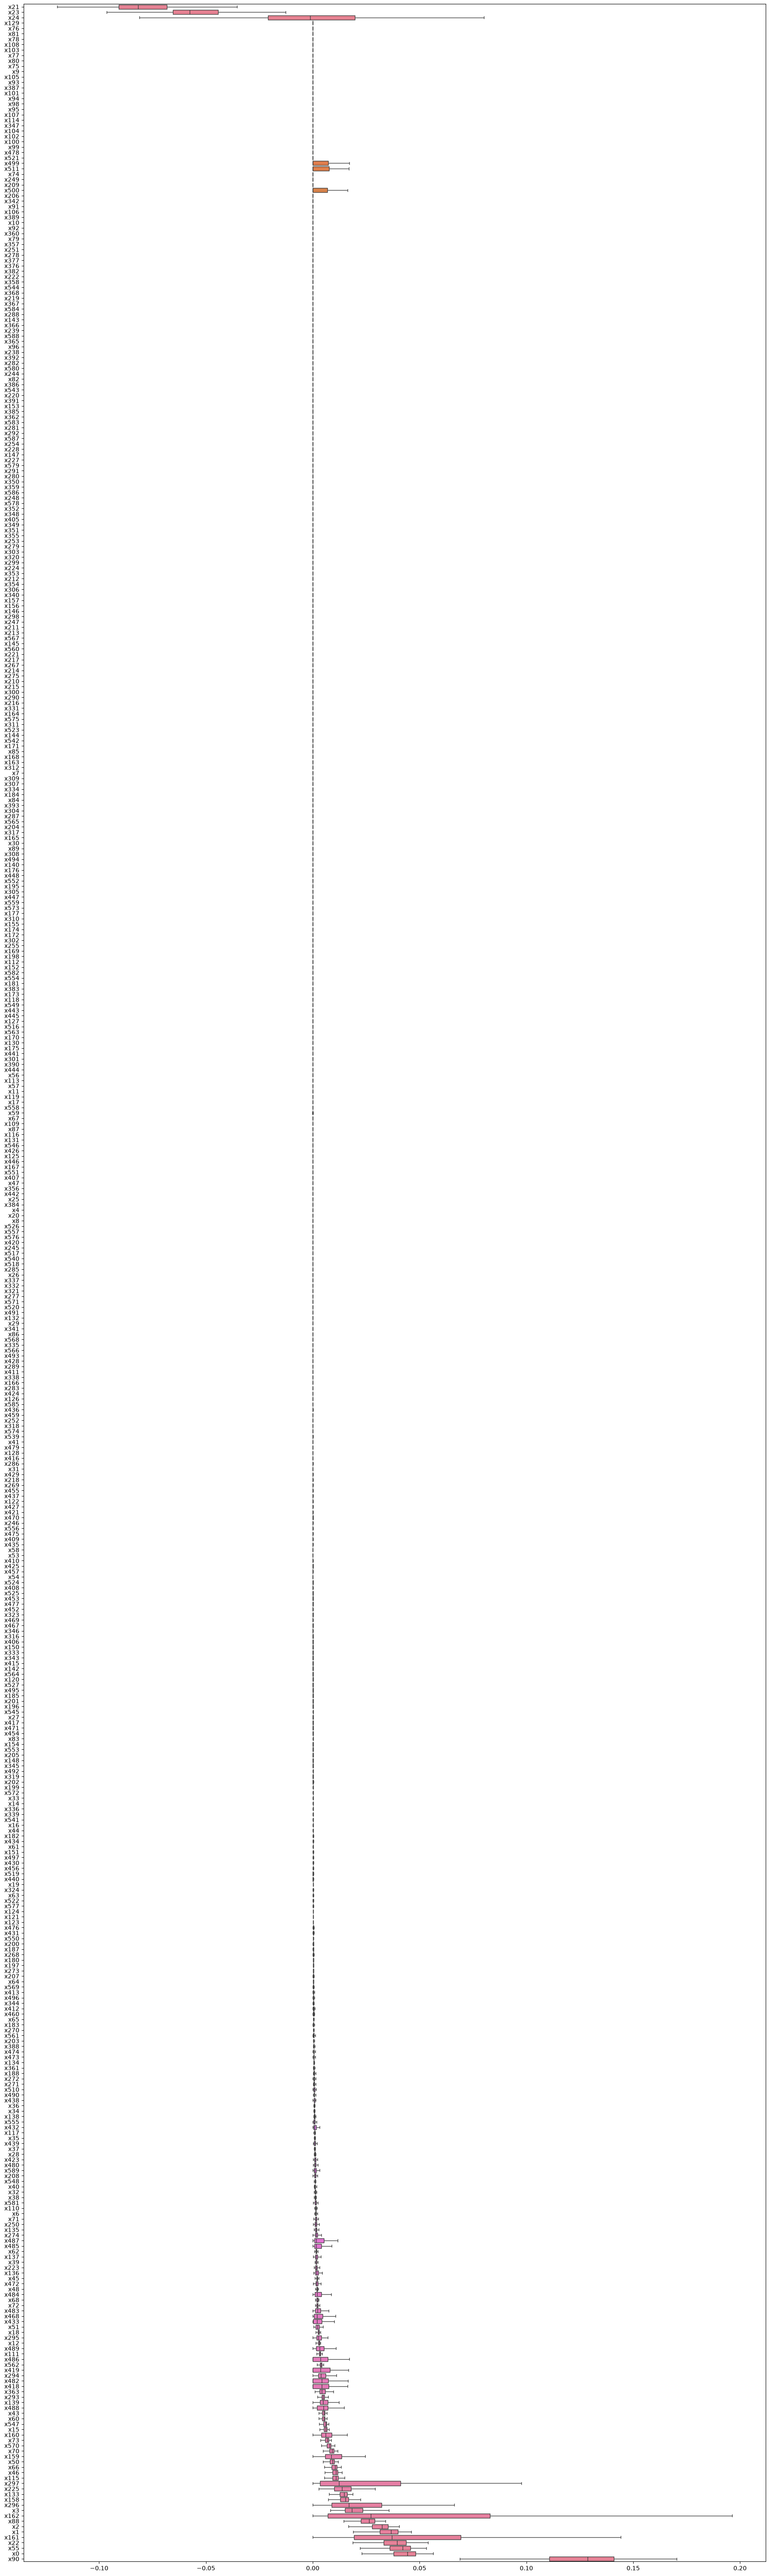

In [77]:
from secomml.data_pipeline import secom_normalizer_scaler
plt.figure(figsize=(18,60))
sns.boxplot(data=secom_normalizer_scaler(X[feat_by_median], norm='l1'), orient='h', showfliers=False)
plt.tight_layout()
plt.show()

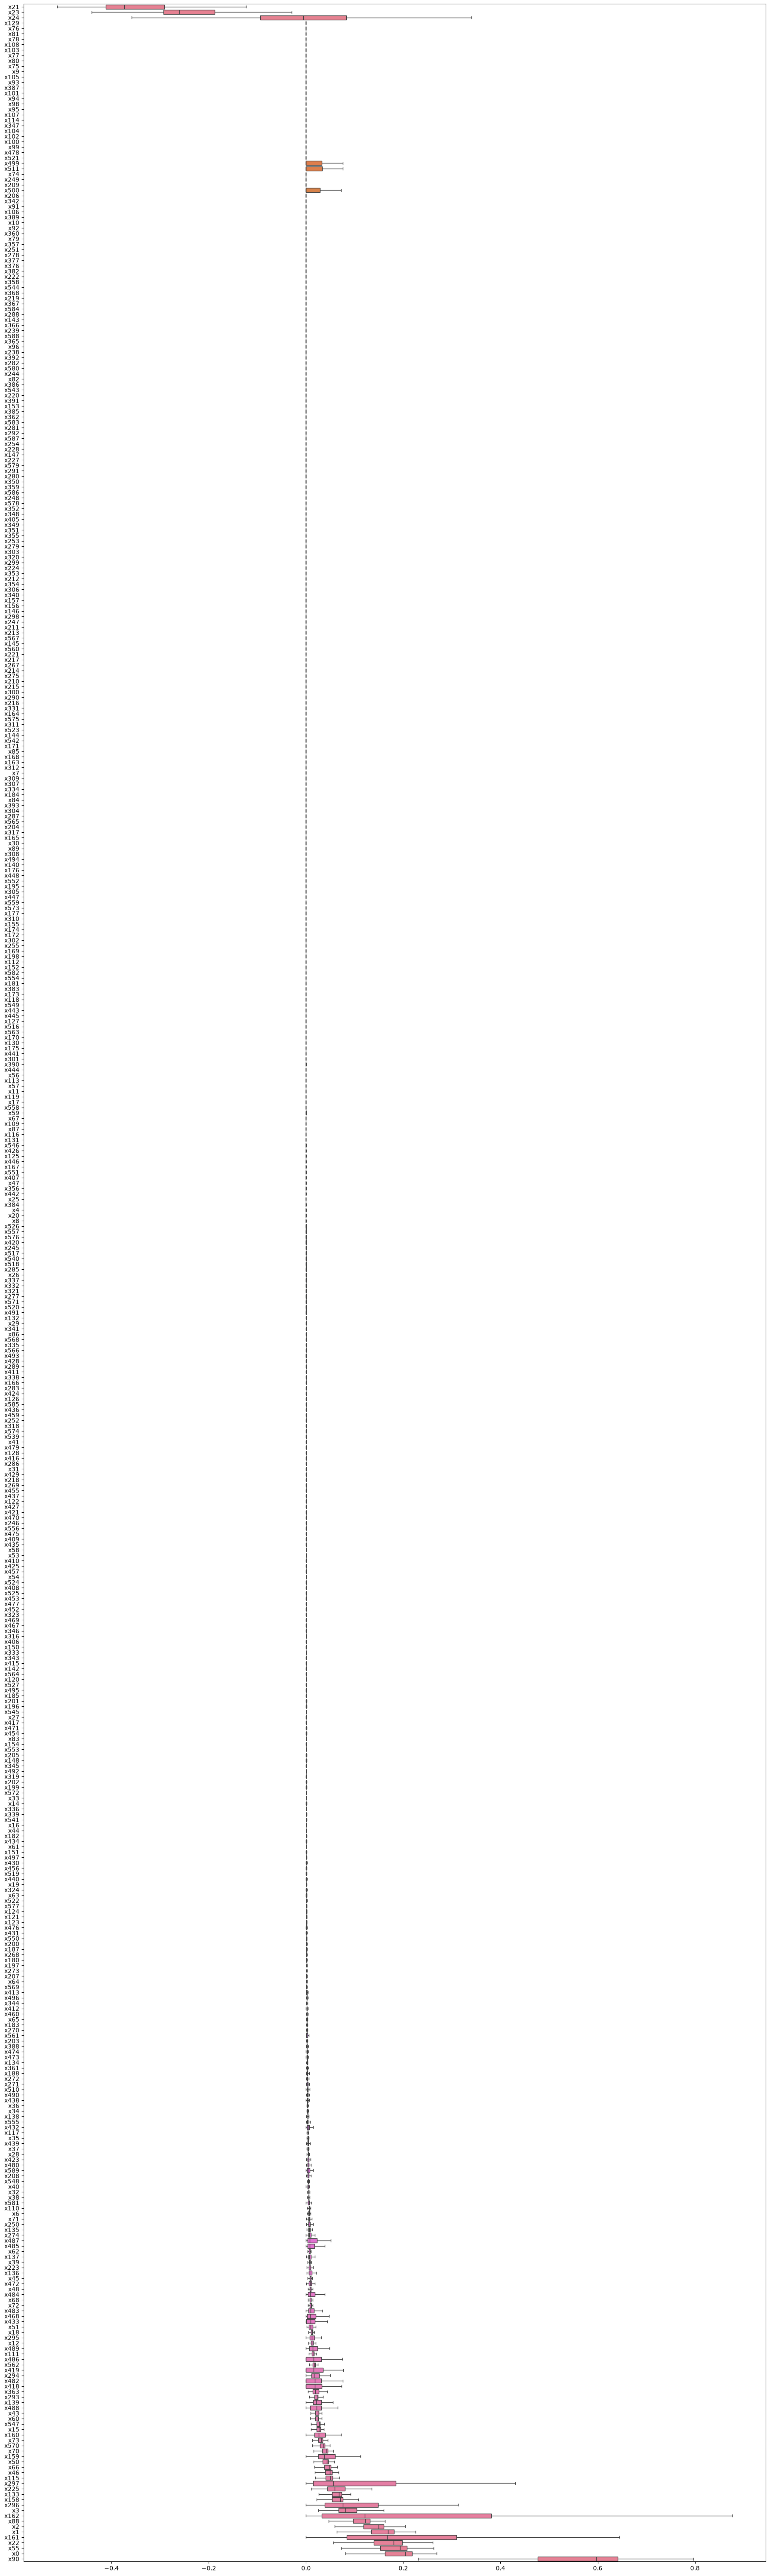

In [78]:
plt.figure(figsize=(18,60))
sns.boxplot(data=secom_normalizer_scaler(X[feat_by_median], norm='l2'), orient='h', showfliers=False)
plt.tight_layout()
plt.show()

### Corelations

### Test